# Data summary figure

Update the methods in the ice-floe-validation-dataset to produce a single figure. For the map image, show a scatter plot and display example 100 km and 500 km boundaries for one case.


/opt/miniconda3/envs/ift_jog/lib/python3.13/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/opt/miniconda3/envs/ift_jog/lib/python3.13/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/opt/miniconda3/envs/ift_jog/lib/python3.13/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/opt/miniconda3/envs/ift_jog/lib/python3.13/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = Da

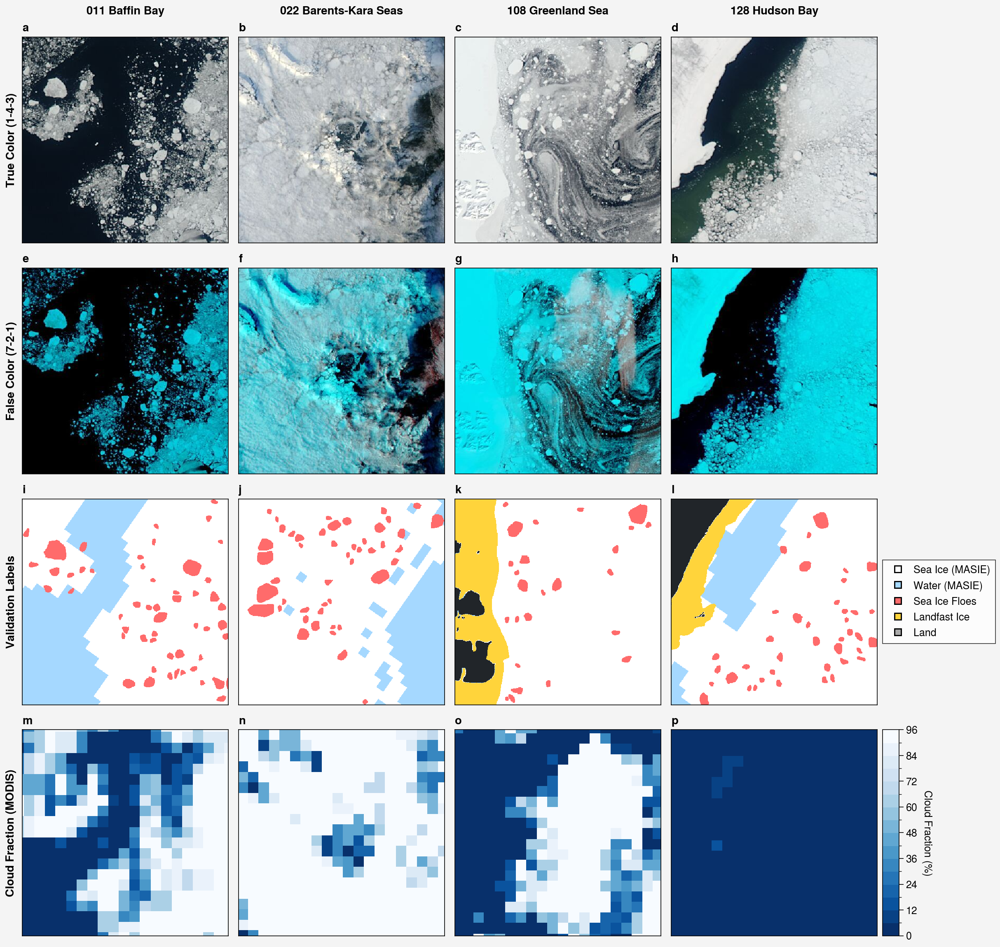

In [3]:
%run ../scripts/plot_dataset_sample.py

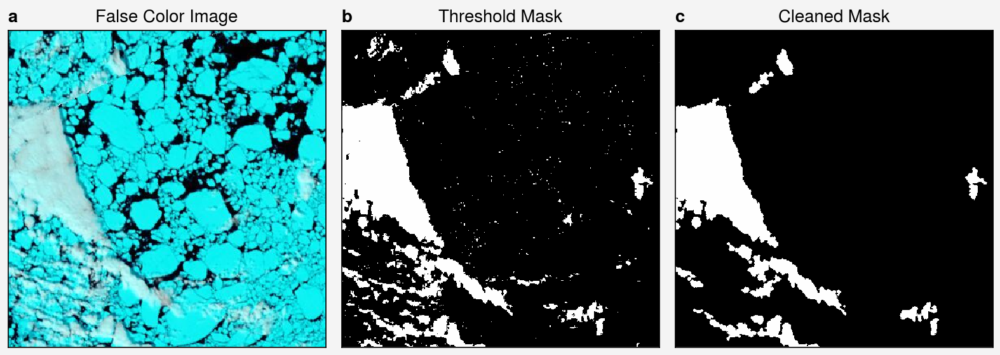

In [4]:
%run ../scripts/plot_cloud_mask_example.py

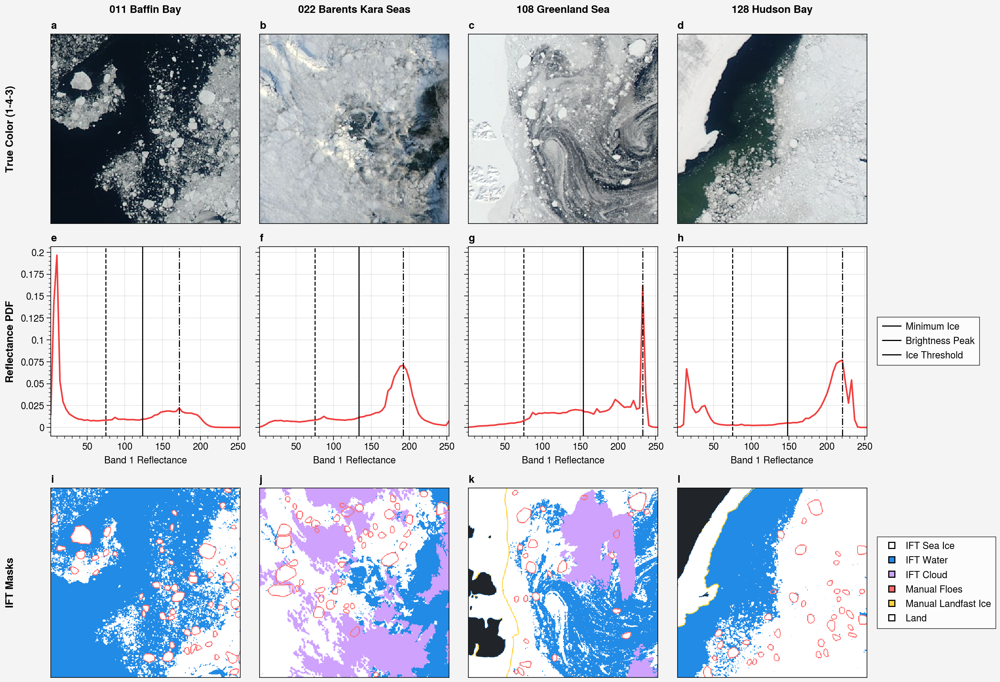

In [12]:
%run ../scripts/plot_masked_img_sample.py

In [2]:
import numpy as np
import os
import pandas as pd
import ultraplot as pplt
import rasterio as rio
from rasterio.plot import reshape_as_image
from sklearn.model_selection import KFold
from scipy.interpolate import interp1d

# Load the list of cloud clearing evaluation cases
dataloc = '../../ice_floe_validation_dataset/'
df = pd.read_csv(dataloc + '/data/validation_dataset/validation_dataset.csv')
df['case_number'] = [str(cn).zfill(3) for cn in df['case_number']]
df.groupby('region').count()
df['start_date'] = pd.to_datetime(df['start_date'].values)
df.index = [cn + '_' + sat for cn, sat in zip(df.case_number, df.satellite)]

def fname(case_data, imtype='labeled_floes'):
    """Generates filenames from rows in the overview table. imtype can be 'labeled_floes', 
    'binary_floes', 'binary_landfast', or 'binary_landmask', 'truecolor', or 'falsecolor'.
    The imtype determines whether a 'png' or 'tiff' is returned.
    """

    cn = case_data['case_number']
    date = pd.to_datetime(case_data['start_date']).strftime('%Y%m%d')
    region = case_data['region']
    sat = case_data['satellite']
    if 'binary' in imtype:
        return  '-'.join([cn, region, date, sat, imtype + '.png'])
        
    elif imtype in ['truecolor', 'falsecolor', 'cloudfraction', 'labeled_floes',]:
        prefix = '-'.join([cn, region, '100km', date])
        return '.'.join([prefix, sat, imtype, '250m', 'tiff'])

    elif imtype in ['seaice', 'landmask',]:
        prefix = '-'.join([cn, region, '100km', date])
        return '.'.join([prefix, 'masie', imtype, '250m', 'tiff'])     

    elif imtype == 'cloudfraction_numeric':
        
        return '-'.join([cn, region, date, sat, 'cloudfraction.csv'])

# Load raster data and masks
fc_dataloc = dataloc + 'data/modis/falsecolor/'
tc_dataloc = dataloc + 'data/modis/truecolor/'
cf_dataloc = dataloc + 'data/modis/cloudfraction_numeric/'

lm_dataloc = dataloc + 'data/validation_dataset/binary_landmask/'
lb_dataloc = dataloc + 'data/validation_dataset/binary_floes/'
lf_dataloc = dataloc + 'data/validation_dataset/binary_landfast/'

masie_ice_loc = dataloc + 'data/masie/seaice/'
masie_land_loc = dataloc + 'data/masie/landmask/'

tc_images = {}
fc_images = {}
cf_images = {}
lb_images = {}
lf_images = {}
lm_images = {}
mi_images = {}
ml_images = {}

missing = []
for row, data in df.iterrows():

    if data.case_number in ['011', '108', '022', '128']:
        
        for datadir, imtype, data_dict in zip([tc_dataloc, fc_dataloc, cf_dataloc,
                                               lb_dataloc, lf_dataloc, lm_dataloc,
                                               masie_ice_loc, masie_land_loc],
                                              ['truecolor', 'falsecolor', 'cloudfraction_numeric',
                                               'binary_floes', 'binary_landfast', 'binary_landmask',
                                               'seaice', 'landmask'],
                                              [tc_images, fc_images, cf_images,
                                               lb_images, lf_images, lm_images,
                                               mi_images, ml_images]):
            try:
                if imtype != 'cloudfraction_numeric':
                    with rio.open(datadir + fname(df.loc[row,:], imtype)) as im:
                        data_dict[row] = im.read()
                else:
                    data_dict[row] = pd.read_csv(datadir + fname(df.loc[row,:], imtype), index_col=0) 
                    data_dict[row].index = data_dict[row].index.astype(int)
                    data_dict[row].columns = data_dict[row].columns.astype(int)
                    
            except:
                if imtype in ['falsecolor', 'cloudfraction_numeric', 'landmask']:
                    print('Couldn\'t read', fname(df.loc[row,:], imtype), imtype)
                elif imtype == 'binary_floes':
                    if df.loc[row, 'visible_floes'] == 'yes':
                        missing.append(fname(df.loc[row,:], imtype))
                elif imtype == 'binary_landfast':
                    if df.loc[row, 'visible_landfast_ice'] == 'yes':
                        missing.append(fname(df.loc[row,:], imtype))
                elif imtype in ['seaice', 'landmask']: # masie images
                    missing.append(fname(df.loc[row,:], imtype))

/opt/miniconda3/envs/calval/lib/python3.13/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/opt/miniconda3/envs/calval/lib/python3.13/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/opt/miniconda3/envs/calval/lib/python3.13/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/opt/miniconda3/envs/calval/lib/python3.13/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = Datase

In [34]:
df.columns

Index(['case_number', 'region', 'start_date', 'center_lon', 'center_lat',
       'center_x', 'center_y', 'month', 'sea_ice_fraction',
       'mean_sea_ice_concentration', 'init_case_number', 'satellite',
       'visible_sea_ice', 'visible_landfast_ice', 'visible_floes',
       'visible_water', 'cloud_fraction_manual', 'cloud_category_manual',
       'artifacts', 'qa_analyst', 'qa_reviewer', 'fl_analyst', 'fl_reviewer',
       'psd_file', 'floe_obscuration', 'landfast_obscuration',
       'modis_cloud_error', 'notes'],
      dtype='object')

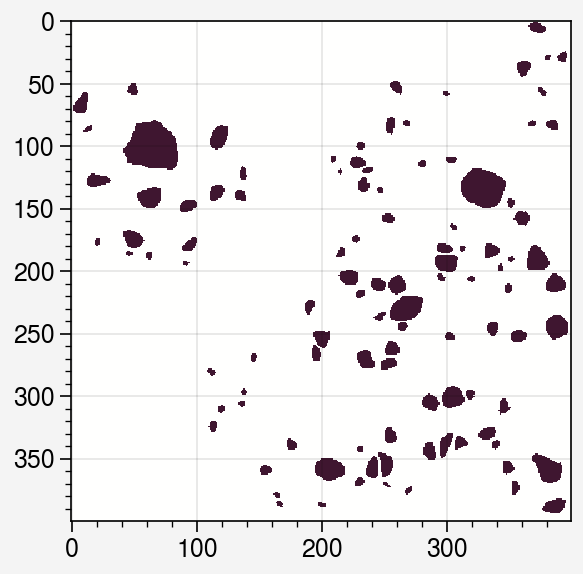

In [23]:
fig, ax = pplt.subplots()
ax.imshow(lb_images['011_aqua'][0,:,:])

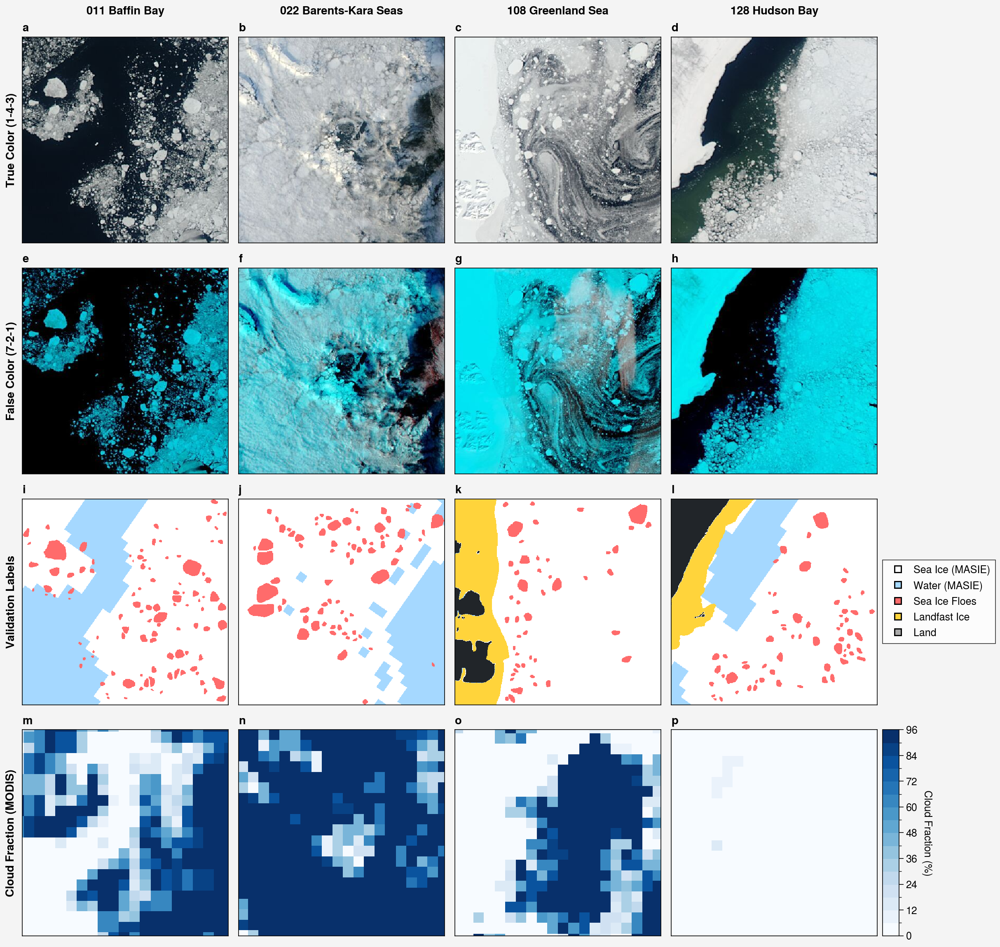

In [57]:
fig, ax = pplt.subplots(nrows=4, ncols=4, share=False)
titles = ['011 Baffin Bay', '022 Barents-Kara Seas', '108 Greenland Sea', '128 Hudson Bay']
for i, case in enumerate(['011', '022', '108', '128']):
    case_number = case + '_aqua'
    ax[0,i].imshow(reshape_as_image(tc_images[case_number]))
    ax[1,i].imshow(reshape_as_image(fc_images[case_number]))
    

        
    masie_ice = mi_images[case_number].squeeze()    
    ax[2,i].imshow(np.ma.masked_array(masie_ice, mask=masie_ice>0), c='blue2')
    
    # landmask
    binary_land = lm_images[case_number][0,:,:]
    ax[2,i].imshow(np.ma.masked_array(binary_land, mask=binary_land == 0), c='gray9')
    
    # labeled floes
    if case_number in lb_images:
        manual_ice = lb_images[case_number][0,:,:]
        ax[2,i].imshow(np.ma.masked_array(manual_ice, mask=manual_ice==0), c='red5')
        
    # labeled landfast
    if case_number in lf_images:
        manual_landfast = lf_images[case_number][0,:,:]
        ax[2,i].imshow(np.ma.masked_array(manual_landfast, mask=manual_landfast == 0), c='yellow4')


    c = ax[3,i].pcolormesh(cf_images[case_number].values, vmin=0, vmax=100, N=17, cmap='Blues')
    
    ax[3,i].format(yreverse=True)

h = []
for color in ['w', 'blue2', 'red5', 'yellow4', 'darkgray']:
    h.append(ax.plot([],[],m='s', lw=0, c=color, edgecolor='k'))

ax[2,-1].legend(h, ['Sea Ice (MASIE)', 'Water (MASIE)', 'Sea Ice Floes', 'Landfast Ice', 'Land'], loc='r', ncols=1)
    
ax[3,-1].colorbar(c, label='Cloud Fraction (%)')
fig.format(abc=True, xticks='none', yticks='none')
fig.format(toplabels=titles, leftlabels=['True Color (1-4-3)', 'False Color (7-2-1)','Validation Labels',  'Cloud Fraction (MODIS)'])
fig.save("../figures/fig_03_validation_dataset_sample.png", dpi=300)

In [58]:
df.loc[[x for x in cf_images], ['start_date', 'center_lat', 'center_lon']]

,start_date,center_lat,center_lon
011_aqua,2011-07-02,72.330328,-70.734736
011_terra,2011-07-02,72.330328,-70.734736
022_aqua,2006-09-09,81.602775,18.083445
022_terra,2006-09-09,81.602775,18.083445
108_aqua,2018-06-10,72.315717,-20.924502
108_terra,2018-06-10,72.315717,-20.924502
128_aqua,2019-04-15,57.853010,-91.984703
128_terra,2019-04-15,57.853010,-91.984703


In [ ]:
  
    # Make the index of the df a unique case label
    df.index = [x.case_number + '_' + x.satellite for row, x in df.iterrows()]
    
    df['cloud_fraction_modis'] = np.nan
    for case in cf_images:
        df.loc[case, 'cloud_fraction_modis'] = np.mean(cf_images[case]/100)
    
    # Plotting images
    # 3 by 2 layout
    # Top row: TC, FC, Cloud Fraction
    # Bottom row: MASIE, Manual Labels, Manual Labels + Clouds
    for case in fc_images:
        region = df.loc[case,'region']
        cf_manual = (df.loc[case, 'cloud_fraction_manual']*100).round(0)
        cf_modis = (df.loc[case, 'cloud_fraction_modis']*100).round(0)
        
        fig, axs = pplt.subplots(ncols=3, nrows=2)
    
        for ax, data, title in zip(axs[0,:], 
                                  [tc_images[case], fc_images[case], cf_images[case]],
                                  ['TC Image', 'FC Image', 'Cloud Fraction (%)']):
            if title in ['TC Image', 'FC Image']:
                ax.imshow(reshape_as_image(data))
            elif title == 'Cloud Fraction (%)':
                c = ax.pcolormesh(data.values, vmin=0, vmax=100, N=17, cmap='Blues')
                ax.colorbar(c, label='Cloud Fraction (%)')
                ax.format(urtitle='Manual: {c0}%\nModis: {c1}'.format(c0=cf_manual, c1=cf_modis))
            ax.format(title=title, yreverse=True)
        
        # plot MASIE data
        ax = axs[1, 0]
        masie_ice = mi_images[case].squeeze()
        masie_land = ml_images[case].squeeze()
        ax.imshow(np.ma.masked_array(masie_land, mask=masie_land != 1), c='steelblue')
        ax.imshow(np.ma.masked_array(masie_ice, mask=masie_ice==0), c='w')
        ax.imshow(np.ma.masked_array(masie_land, mask=masie_land != 2), c='gray')
        ax.imshow(np.ma.masked_array(masie_land, mask=masie_land != 4), c='darkgray')
        h = []
        for c in ['steelblue', 'w', 'lightgray', 'darkgray']:
            h.append(ax.plot([],[],m='s', lw=0, c=c, edgecolor='k'))
        ax.legend(h, ['Water', 'Ice', 'Coast', 'Land'], loc='b', ncols=2)
        ax.format(title='MASIE')
        
        
        # plot manual label data on the next two axes
        binary_land = lm_images[case][0,:,:]
        clouds25 = (cf_images[case] >= 25).astype(int)
        clouds50 = (cf_images[case] >= 50).astype(int)
        clouds = (clouds25 + clouds50)/2
    
        for ax in axs[1, 1:]:
            ax.imshow(np.ma.masked_array(binary_land, mask=binary_land == 0), c='gray9')
            if case in lb_images:
                manual_ice = lb_images[case][0,:,:]
                ax.imshow(np.ma.masked_array(manual_ice, mask=manual_ice==0), c='red5')
            else:
                ax.format(ultitle='No ice mask')
            
            if case in lf_images:
                manual_landfast = lf_images[case][0,:,:]
                ax.imshow(np.ma.masked_array(manual_landfast, mask=manual_landfast == 0), c='yellow4')
            else:
                ax.format(urtitle='No landfast mask')
    
        # Overlay clouds on last pannel
        ax.imshow(np.ma.masked_array(clouds, mask=clouds==0), cmap='Blues', vmin=0, vmax=2, alpha=0.5)
            
        h = []
        for c in ['red5', 'yellow4', 'darkgray', 'lightblue']:
            h.append(ax.plot([],[],m='s', lw=0, c=c, edgecolor='k'))
    
        axs[1,1].legend(h[:-1], ['Sea Ice', 'Landfast Ice', 'Land'], loc='b', ncols=2)
        axs[1,1].format(title='Manual Labels')
        
            
        axs[1,2].legend(h, ['Sea Ice', 'Landfast Ice', 'Land', 'MODIS cloud'], loc='b', ncols=2)
        axs[1,2].format(title='Manual Labels + Cloud')
        
        axs.format(yreverse=True, suptitle=case.replace('_', ' ').title() + ' ' + region.replace('_', ' ').title())
        fig.save('../data/validation_dataset/quicklook_images/' + case + '_' + region + '_quicklook.png', dpi=300)
        pplt.close(fig)

In [59]:
# Cloud mask visualization
# False color image, with bright clouds
# Speckled interim image
# Cleaned image

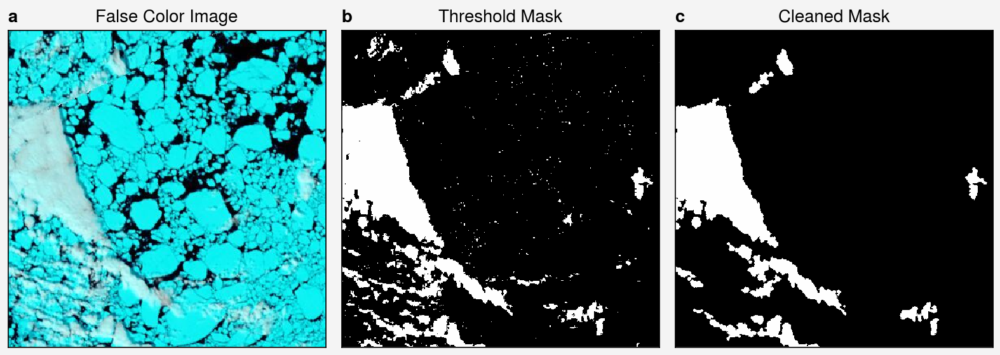

In [3]:
import numpy as np
import pandas as pd
import ultraplot as pplt
import rasterio as rio
from rasterio.plot import reshape_as_image
import skimage

# Load the list of cloud clearing evaluation cases
dataloc = '../../ice_floe_validation_dataset/'
df = pd.read_csv(dataloc + '/data/validation_dataset/validation_dataset.csv')
df['case_number'] = [str(cn).zfill(3) for cn in df['case_number']]
df.groupby('region').count()
df['start_date'] = pd.to_datetime(df['start_date'].values)
df.index = [cn + '_' + sat for cn, sat in zip(df.case_number, df.satellite)]

def fname(case_data, imtype='labeled_floes'):
    """Generates filenames from rows in the overview table. imtype can be 'labeled_floes', 
    'binary_floes', 'binary_landfast', or 'binary_landmask', 'truecolor', or 'falsecolor'.
    The imtype determines whether a 'png' or 'tiff' is returned.
    """

    cn = case_data['case_number']
    date = pd.to_datetime(case_data['start_date']).strftime('%Y%m%d')
    region = case_data['region']
    sat = case_data['satellite']
    if 'binary' in imtype:
        return  '-'.join([cn, region, date, sat, imtype + '.png'])
        
    elif imtype in ['truecolor', 'falsecolor', 'cloudfraction', 'labeled_floes',]:
        prefix = '-'.join([cn, region, '100km', date])
        return '.'.join([prefix, sat, imtype, '250m', 'tiff'])

    elif imtype in ['seaice', 'landmask',]:
        prefix = '-'.join([cn, region, '100km', date])
        return '.'.join([prefix, 'masie', imtype, '250m', 'tiff'])     

    elif imtype == 'cloudfraction_numeric':
        
        return '-'.join([cn, region, date, sat, 'cloudfraction.csv'])


case = '006_terra'
fc_dataloc = dataloc + 'data/modis/falsecolor/'

with rio.open(fc_dataloc + fname(df.loc[case,:], 'falsecolor')) as im:
    fc_img = im.read()

# with rio.open(lm_dataloc + fname(df.loc[case,:], 'binary_landmask')) as im:
#     landmask = im.read()

initial = skimage.io.imread("../data/ift_cloud_mask/initial/006-baffin_bay-100km-20220530-terra-250m-cloudmask.png")
cleaned = skimage.io.imread("../data/ift_cloud_mask/cleaned/006-baffin_bay-100km-20220530-terra-250m-cloudmask.png")

fig, ax = pplt.subplots(ncols=3)
ax[0].imshow(reshape_as_image(fc_img))
ax[1].imshow(initial, cmap='mono_r')
ax[2].imshow(cleaned, cmap='mono_r')
ax[0].format(title='False Color Image')
ax[1].format(title='Threshold Mask')
ax[2].format(title='Cleaned Mask')
fig.format(xticks='none', yticks='none', abc=True)
fig.save('../figures/fig_06_cloud_mask_example.png', dpi=300)

# Show example of classification steps
- Sea ice mask
- Bright ice mask
- Cloud mask

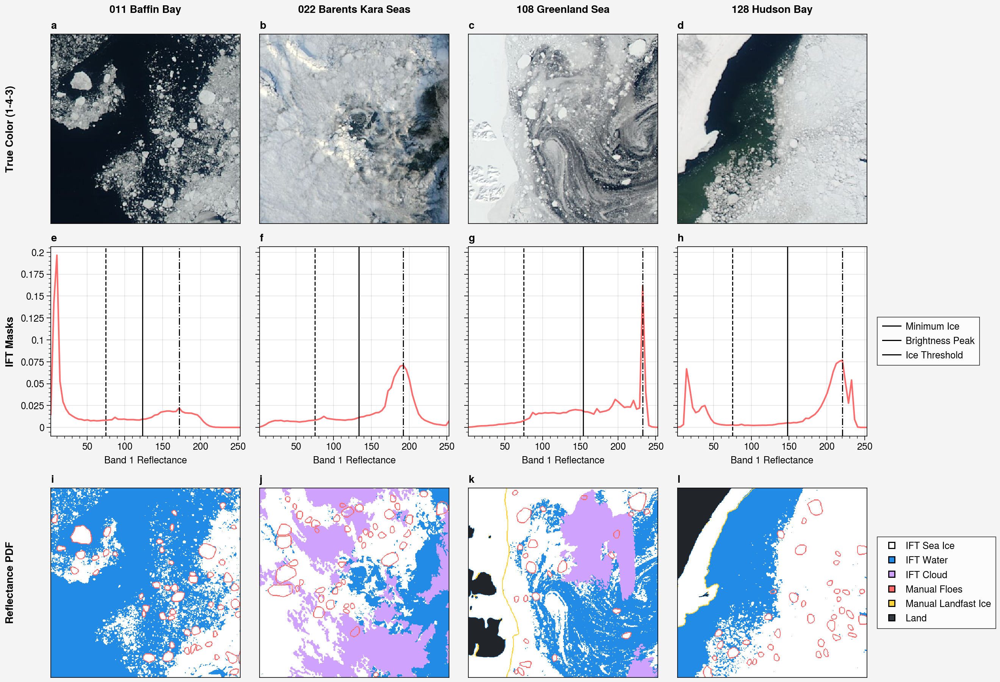

In [2]:
import numpy as np
import os
import pandas as pd
import ultraplot as pplt
import skimage.io as io
from skimage.morphology import dilation, erosion

# Load the list of cloud clearing evaluation cases
dataloc = '../../ice_floe_validation_dataset/'
df = pd.read_csv(dataloc + '/data/validation_dataset/validation_dataset.csv')
df['case_number'] = [str(cn).zfill(3) for cn in df['case_number']]
df.groupby('region').count()
df['start_date'] = pd.to_datetime(df['start_date'].values)
df.index = [cn + '_' + sat for cn, sat in zip(df.case_number, df.satellite)]

def fname(case_data, imtype='labeled_floes'):
    """Generates filenames from rows in the overview table. imtype can be 'labeled_floes', 
    'binary_floes', 'binary_landfast', or 'binary_landmask', 'truecolor', or 'falsecolor'.
    The imtype determines whether a 'png' or 'tiff' is returned.
    """

    cn = case_data['case_number']
    date = pd.to_datetime(case_data['start_date']).strftime('%Y%m%d')
    region = case_data['region']
    sat = case_data['satellite']
    if 'binary' in imtype:
        return  '-'.join([cn, region, date, sat, imtype + '.png'])       
    elif imtype in ['truecolor', 'falsecolor', 'cloudfraction', 'labeled_floes',]:
        prefix = '-'.join([cn, region, '100km', date])
        return '.'.join([prefix, sat, imtype, '250m', 'tiff'])
    elif imtype in ['seaice', 'landmask',]:
        prefix = '-'.join([cn, region, '100km', date])
        return '.'.join([prefix, 'masie', imtype, '250m', 'tiff'])     

# Load raster data and masks
tc_dataloc = dataloc + 'data/modis/truecolor/'
lm_dataloc = dataloc + 'data/validation_dataset/binary_landmask/'
lb_dataloc = dataloc + 'data/validation_dataset/binary_floes/'
lf_dataloc = dataloc + 'data/validation_dataset/binary_landfast/'
ice_mask_loc = '../data/ift_prelim_ice_mask/'
cloud_mask_loc = '../data/ift_cloud_mask/cleaned/'

tc_images = {}
lb_images = {}
lf_images = {}
lm_images = {}
ice_mask_images = {}
cloud_mask_images = {}

missing = []
plot_cases = ['011', '022', '108', '128']
for row, data in df.iterrows():
    cn = data['case_number']
    date = pd.to_datetime(data['start_date']).strftime('%Y%m%d')
    region = data['region']
    sat = data['satellite']
    
    if cn in plot_cases:

        prefix = '-'.join([cn, region, '100km', date])        
        tc_images[row] = io.imread(tc_dataloc + '.'.join([prefix, sat, 'truecolor', '250m', 'tiff']))
        lb_images[row] = io.imread(lb_dataloc +  '-'.join([cn, region, date, sat, 'binary_floes' + '.png']))
        lf_images[row] = io.imread(lf_dataloc +  '-'.join([cn, region, date, sat, 'binary_landfast' + '.png']))
        lm_images[row] = io.imread(lm_dataloc +  '-'.join([cn, region, date, sat, 'binary_landmask' + '.png']))
        ice_mask_images[row] = io.imread(ice_mask_loc +  '-'.join([cn, region, '100km', date, sat, '250m', 'prelim_icemask' + '.png']))
        cloud_mask_images[row] = io.imread(cloud_mask_loc +  '-'.join([cn, region, '100km', date, sat, '250m', 'cloudmask' + '.png']))

fig, ax = pplt.subplots(nrows=3, ncols=4, sharex=False, sharey=True)
titles = []
for i, case_number in enumerate(plot_cases):
    case = case_number + '_aqua'
    region = df.loc[case, 'region'].replace('_', ' ').title()
    titles.append(str(case_number) + ' ' + region)
    ax[0,i].imshow(tc_images[case])
    
    ice_mask = ice_mask_images[case][:,:]
    ax[2,i].imshow(np.ma.masked_array(ice_mask, mask=ice_mask > 0), c='blue6')
    ax[2,i].imshow(np.ma.masked_array(ice_mask, mask=ice_mask == 0), c='w')

    cloud_mask = cloud_mask_images[case][:,:]
    ax[2,i].imshow(np.ma.masked_array(cloud_mask, mask=cloud_mask == 0), c='lilac')
    
    land_mask = lm_images[case][:,:]
    ax[2,i].imshow(np.ma.masked_array(land_mask, mask=land_mask == 0), c='gray9')
    
    # labeled floes
    if case in lb_images:
        if len(lb_images[case].shape) == 3:
            manual_ice = lb_images[case][:,:,0]
        else:
            manual_ice = lb_images[case][:,:]
        outlines = dilation(manual_ice) - erosion(manual_ice)
        ax[2,i].imshow(np.ma.masked_array(outlines, mask=outlines==0), c='red5', alpha=1)
        
    # labeled landfast
    if case in lf_images:
        if len(lf_images[case].shape) == 3:
            manual_landfast = lf_images[case][:,:,0]
        else:
            manual_landfast = lf_images[case][:,:]
        
        land_buffer = dilation(land_mask)
        manual_landfast[land_buffer > 0] = 255
        outlines = dilation(manual_landfast) - erosion(manual_landfast)
        ax[2,i].imshow(np.ma.masked_array(outlines, mask=outlines == 0), c='yellow4')

    red_band = tc_images[case][:,:,0].copy()
    red_band[cloud_mask > 0] = 0
    red_band[land_mask > 0] = 0
    
    data = np.ravel(red_band)
    data = data[data > 0]
    y, xe = np.histogram(data, bins=np.linspace(0, 255, 64))
    xc = (xe[1:] + xe[:-1]) / 2

    ax[1, i].plot(xc, y / np.sum(y), color='red5')
    
    idxmax = y[xc > 75].argmax()
    peak_loc = xc[xc > 75][idxmax]
    ax[1, i].axvline(75, lw=1, color='k', ls='--')
    ax[1, i].axvline(peak_loc, lw=1, color='k', ls='-.')
    ax[1, i].axvline(0.5 * (75 + peak_loc), lw=1, color='k', ls='-')
    
    ax[1, i].format(ylabel='', xlabel='Band 1 Reflectance')

for j in [0, 2]:
    for i in range(0, 4):
        ax[j, i].format(xticks='none', yticks='none')

h = []
for color in ['w', 'blue6', 'lilac', 'red5', 'yellow4', 'gray8']:
    h.append(ax.plot([],[],m='s', lw=0, c=color, edgecolor='k'))
ax[2,-1].legend(h, ['IFT Sea Ice', 'IFT Water', 'IFT Cloud', 'Manual Floes', 'Manual Landfast Ice', 'Land'], loc='r', ncols=1)

h = []
for ls in ['--', '-.', '-']:
    h.append(ax.plot([],[],m='', lw=1, color='k'))
ax[1,-1].legend(h, ['Minimum Ice', 'Brightness Peak', 'Ice Threshold'], loc='r', ncols=1)

fig.format(abc=True)
fig.format(toplabels=titles, leftlabels=['True Color (1-4-3)', 'IFT Masks', 'Reflectance PDF'])
fig.save("../figures/fig_07_ice_water_discrimination.png", dpi=300)

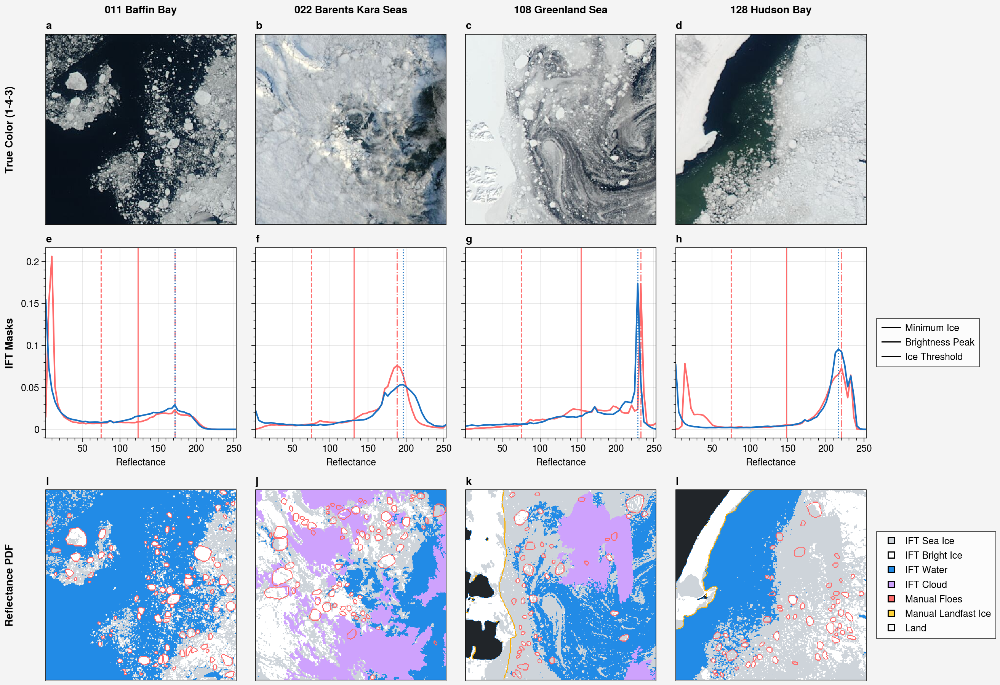

In [27]:
import numpy as np
import os
import pandas as pd
import ultraplot as pplt
import skimage.io as io
from skimage.morphology import dilation, erosion

# Load the list of cloud clearing evaluation cases
dataloc = '../../ice_floe_validation_dataset/'
df = pd.read_csv(dataloc + '/data/validation_dataset/validation_dataset.csv')
df['case_number'] = [str(cn).zfill(3) for cn in df['case_number']]
df.groupby('region').count()
df['start_date'] = pd.to_datetime(df['start_date'].values)
df.index = [cn + '_' + sat for cn, sat in zip(df.case_number, df.satellite)]

def fname(case_data, imtype='labeled_floes'):
    """Generates filenames from rows in the overview table. imtype can be 'labeled_floes', 
    'binary_floes', 'binary_landfast', or 'binary_landmask', 'truecolor', or 'falsecolor'.
    The imtype determines whether a 'png' or 'tiff' is returned.
    """

    cn = case_data['case_number']
    date = pd.to_datetime(case_data['start_date']).strftime('%Y%m%d')
    region = case_data['region']
    sat = case_data['satellite']
    if 'binary' in imtype:
        return  '-'.join([cn, region, date, sat, imtype + '.png'])       
    elif imtype in ['truecolor', 'falsecolor', 'cloudfraction', 'labeled_floes',]:
        prefix = '-'.join([cn, region, '100km', date])
        return '.'.join([prefix, sat, imtype, '250m', 'tiff'])
    elif imtype in ['seaice', 'landmask',]:
        prefix = '-'.join([cn, region, '100km', date])
        return '.'.join([prefix, 'masie', imtype, '250m', 'tiff'])     

# Load raster data and masks
tc_dataloc = dataloc + 'data/modis/truecolor/'
fc_dataloc = dataloc + 'data/modis/falsecolor/'
lm_dataloc = dataloc + 'data/validation_dataset/binary_landmask/'
lb_dataloc = dataloc + 'data/validation_dataset/binary_floes/'
lf_dataloc = dataloc + 'data/validation_dataset/binary_landfast/'
ice_mask_loc = '../data/ift_prelim_ice_mask/'
cloud_mask_loc = '../data/ift_cloud_mask/cleaned/'

tc_images = {}
fc_images = {}
lb_images = {}
lf_images = {}
lm_images = {}
ice_mask_images = {}
cloud_mask_images = {}

missing = []
plot_cases = ['011', '022', '108', '128']
for row, data in df.iterrows():
    cn = data['case_number']
    date = pd.to_datetime(data['start_date']).strftime('%Y%m%d')
    region = data['region']
    sat = data['satellite']
    
    if cn in plot_cases:

        prefix = '-'.join([cn, region, '100km', date])        
        tc_images[row] = io.imread(tc_dataloc + '.'.join([prefix, sat, 'truecolor', '250m', 'tiff']))
        fc_images[row] = io.imread(fc_dataloc + '.'.join([prefix, sat, 'falsecolor', '250m', 'tiff']))
        lb_images[row] = io.imread(lb_dataloc +  '-'.join([cn, region, date, sat, 'binary_floes' + '.png']))
        lf_images[row] = io.imread(lf_dataloc +  '-'.join([cn, region, date, sat, 'binary_landfast' + '.png']))
        lm_images[row] = io.imread(lm_dataloc +  '-'.join([cn, region, date, sat, 'binary_landmask' + '.png']))
        ice_mask_images[row] = io.imread(ice_mask_loc +  '-'.join([cn, region, '100km', date, sat, '250m', 'prelim_icemask' + '.png']))
        cloud_mask_images[row] = io.imread(cloud_mask_loc +  '-'.join([cn, region, '100km', date, sat, '250m', 'cloudmask' + '.png']))

fig, ax = pplt.subplots(nrows=3, ncols=4, sharex=False, sharey=True)
titles = []
for i, case_number in enumerate(plot_cases):
    case = case_number + '_aqua'
    region = df.loc[case, 'region'].replace('_', ' ').title()
    titles.append(str(case_number) + ' ' + region)
    ax[0,i].imshow(tc_images[case])
    
    ice_mask = ice_mask_images[case][:,:]
    cloud_mask = cloud_mask_images[case][:,:]
    land_mask = lm_images[case][:,:]

    # Band 1
    red_band = tc_images[case][:,:,0].copy()
    red_band[cloud_mask > 0] = 0
    red_band[land_mask > 0] = 0
    
    data = np.ravel(red_band)
    data = data[data > 0]
    y, xe = np.histogram(data, bins=np.linspace(0, 255, 64))
    xc = (xe[1:] + xe[:-1]) / 2

    ax[1, i].plot(xc, y / np.sum(y), color='red5', label='Band 1')
    
    idxmax = y[xc > 75].argmax()
    peak_loc = xc[xc > 75][idxmax]

    bright_ice = ice_mask & (red_band >= peak_loc)
    
    ax[1, i].axvline(75, lw=1, color='red5', ls='--')
    ax[1, i].axvline(peak_loc, lw=1, color='red5', ls='-.')
    ax[1, i].axvline(0.5 * (75 + peak_loc), lw=1, color='red5', ls='-')
    
    ax[1, i].format(ylabel='', xlabel='Reflectance')

    # Band 2
    nir_band = fc_images[case][:,:,1].copy()
    nir_band[cloud_mask > 0] = 0
    nir_band[land_mask > 0] = 0
    
    data = np.ravel(nir_band)
    data = data[data > 0]
    y, xe = np.histogram(data, bins=np.linspace(0, 255, 64))
    xc = (xe[1:] + xe[:-1]) / 2

    ax[1, i].plot(xc, y / np.sum(y), color='blue8', label='Band 2')
    
    idxmax = y[xc > 75].argmax()
    peak_loc = xc[xc > 75][idxmax]
    bright_ice = ice_mask & (bright_ice | (nir_band >= peak_loc))
    # ax[1, i].axvline(75, lw=1, color='k', ls='--')
    ax[1, i].axvline(peak_loc, lw=1, color='blue8', ls=':')
    # ax[1, i].axvline(0.5 * (75 + peak_loc), lw=1, color='k', ls='-')

    

    ax[2,i].imshow(np.ma.masked_array(ice_mask, mask=ice_mask > 0), c='blue6')
    ax[2,i].imshow(np.ma.masked_array(ice_mask, mask=ice_mask == 0), c='gray4')
    ax[2,i].imshow(np.ma.masked_array(bright_ice, mask=bright_ice == 0), c='w')
    
    
    ax[2,i].imshow(np.ma.masked_array(cloud_mask, mask=cloud_mask == 0), c='lilac')
    ax[2,i].imshow(np.ma.masked_array(land_mask, mask=land_mask == 0), c='gray9')
    
    # labeled floes
    if case in lb_images:
        if len(lb_images[case].shape) == 3:
            manual_ice = lb_images[case][:,:,0]
        else:
            manual_ice = lb_images[case][:,:]
        outlines = dilation(manual_ice) - erosion(manual_ice)
        ax[2,i].imshow(np.ma.masked_array(outlines, mask=outlines==0), c='red5', alpha=1)
  
    # labeled landfast
    if case in lf_images:
        if len(lf_images[case].shape) == 3:
            manual_landfast = lf_images[case][:,:,0]
        else:
            manual_landfast = lf_images[case][:,:]
        
        land_buffer = dilation(land_mask)
        manual_landfast[land_buffer > 0] = 255
        outlines = dilation(manual_landfast) - erosion(manual_landfast)
        ax[2,i].imshow(np.ma.masked_array(outlines, mask=outlines == 0), c='yellow6')


for j in [0, 2]:
    for i in range(0, 4):
        ax[j, i].format(xticks='none', yticks='none')

h = []
for color in ['gray4', 'w', 'blue6', 'lilac', 'red5', 'yellow4', 'gray0']:
    h.append(ax.plot([],[],m='s', lw=0, c=color, edgecolor='k'))
ax[2,-1].legend(h, ['IFT Sea Ice', 'IFT Bright Ice', 'IFT Water', 'IFT Cloud', 'Manual Floes', 'Manual Landfast Ice', 'Land'], loc='r', ncols=1)

h = []
for ls in ['--', '-.', '-']:
    h.append(ax.plot([],[],m='', lw=1, color='k'))
ax[1,-1].legend(h, ['Minimum Ice', 'Brightness Peak', 'Ice Threshold'], loc='r', ncols=1)

fig.format(abc=True)
fig.format(toplabels=titles, leftlabels=['True Color (1-4-3)', 'IFT Masks', 'Reflectance PDF'])
fig.save("../figures/fig_07_ice_water_discrimination.png", dpi=300)

In [13]:
tc_images['011_aqua'].shape

(400, 400, 4)

In [12]:
fc_images['011_aqua'].shape

(4, 400, 400)

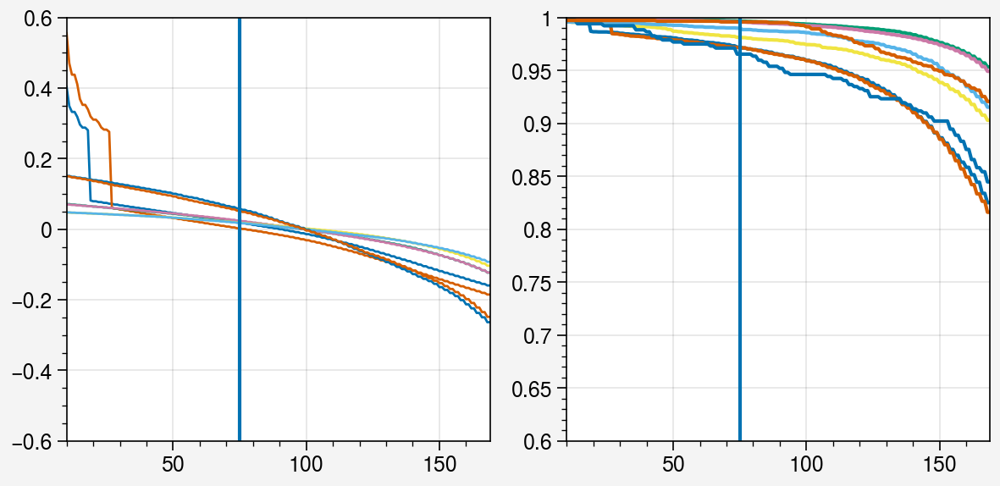

In [102]:
# Basic sensitivity test
fig, ax = pplt.subplots(ncols=2, sharey=False)
for case in tc_images:
    red_band = tc_images[case][:,:,0].copy()
    cloud_mask = cloud_mask_images[case][:,:]
    land_mask = lm_images[case][:,:]
    red_band[cloud_mask > 0] = 0
    red_band[land_mask > 0] = 0
    
    sea_ice_fraction = []
    floe_fraction = []
    data = np.ravel(red_band)
    comp_idx = data > 0
    data = data[comp_idx]

    # Manually validated floes in clear-sky conditions
    manual_floes = np.ravel(lb_images[case][:,:,0])[comp_idx]
    
    for init_ice in range(10, 170):
        y, xe = np.histogram(data, bins=np.linspace(0, 255, 64))
        xc = (xe[1:] + xe[:-1]) / 2
        
        idxmax = y[xc > init_ice].argmax()
        peak_loc = xc[xc > init_ice][idxmax]
        thresh = 0.5 * (init_ice + peak_loc)
        sea_ice_fraction.append(np.mean(data >= thresh))
        floe_fraction.append(np.sum(manual_floes[data >= thresh]) / np.sum(manual_floes))
    sea_ice_fraction = np.array(sea_ice_fraction)
    ax[0].plot(range(10, 170), sea_ice_fraction - np.mean(sea_ice_fraction), lw=1)
    ax[1].plot(range(10, 170), floe_fraction)
ax[0].axvline(75)
ax[1].axvline(75)
ax[1].format(ylim=(0.6, 1))
ax[0].format(ylim=(-0.6, 0.6))

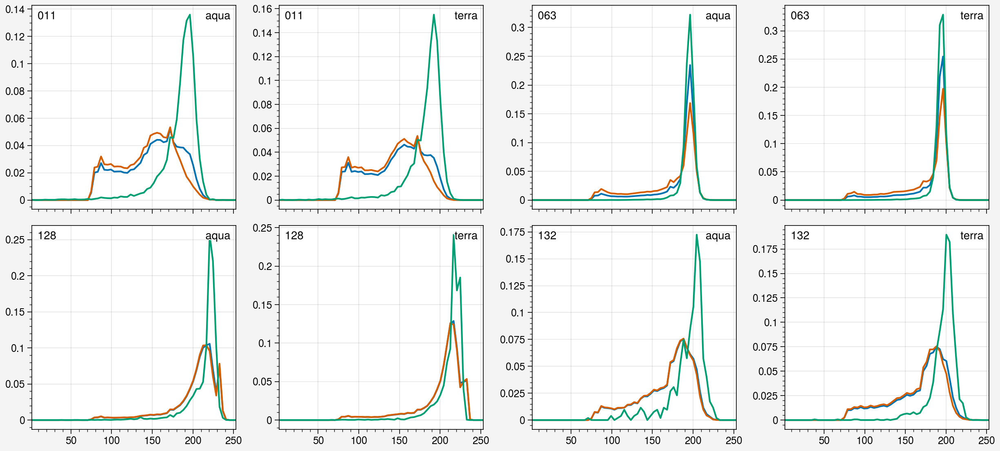

In [115]:
fig, axs = pplt.subplots(ncols=int(len(tc_images.keys()) / 2), nrows=2, sharey=False)
for ax, case in zip(axs, tc_images):
    red_band = tc_images[case][:,:,0].copy()
    cloud_mask = cloud_mask_images[case][:,:]
    land_mask = lm_images[case][:,:]
    red_band[cloud_mask > 0] = 0
    red_band[land_mask > 0] = 0
    
    sea_ice_fraction = []
    floe_fraction = []
    data = np.ravel(red_band)
    comp_idx = data > 0
    data = data[comp_idx]

    # Manually validated floes in clear-sky conditions
    manual_floes = np.ravel(lb_images[case][:,:,0])[comp_idx]

    y_all, xe = np.histogram(data[(data > 75)], bins=np.linspace(0, 255, 64))
    y_non_floes, xe = np.histogram(data[(data > 75) & (manual_floes == 0)], bins=np.linspace(0, 255, 64))
    y_floes, xe = np.histogram(data[manual_floes > 0], bins=np.linspace(0, 255, 64))
    xc = (xe[1:] + xe[:-1]) / 2

    ax.plot(xc, y_all / np.sum(y_all))
    ax.plot(xc, y_non_floes / np.sum(y_non_floes))
    ax.plot(xc, y_floes / np.sum(y_floes))
    ax.format(ultitle=case.split('_')[0], urtitle=case.split('_')[1])

# Next Steps
- Write up description of method to find "brightest floes"
- Can use the first-nonzero method with a threshold, like first try the ones brighter than the peak brightness in the region, then try the ones larger than a particular percentile.